I want to try a new nerual network architecture. 
The idea is that we get X input data sense data, then we encode it to our embedding space, here we do the thinking. 
The thinking is done as follows, we have two units, L1 thinking and L2 thinking. We have G1 = G2, the nodes in L1 and L2, say they're = 100 for this example. We have another hyperparameter, the split factor, SF1 and SF2 which is the amount of connections out from each node. To understand how these nodes are connected, label the nodes in L1 1-100 and the nodes in L2 1-100B. Now I will describe the adjacency graph the adjacency graph has weights, when we pass the initial thought vector t_0 through the network we calculate the adjacency matrix M_adj times the thought, like this: A(M_adj t_0) where A is your chosen activation function, of note, the adjacency matrix is defined like this: the column is which node the edge points to and the rowname is where it is coming from. So the nodes are connected as follows: all nodes are connected to themselves, the diagonal iss initialized as 1. Node 1 points to node 2 which points to node 3... and node 100 points to node 1 in a circle. The split factor say it is 4, then node 1 points to node 100//(4+1) = 20 and points to node 40, 60 and 80. We are basically approximating a fully connected graph. The nodes in L2 are connected in the same way amongst themselves, according to G2 and SF2. between L1 and L2 we have a dense layer with G1//2 this 2 should be a hyperparameter. So we downproject the L1 thinking and then feed this into L2. L1 -> 50 dim -> fully connected -> L2. We have no activation functions yet. The whole thing is only an adjacency graph times the initial value vector, our t_0. t_0 is initialized as follows, L1 nodes have their values from the encoder applied to X. L2 nodes are initialized as 0, the dense neural pathway also has 0s as initial values. 
We also need biases for each node, each itteration we add the biases before applying activations.  
We apply t_1 = A(M_adj t_0 + biases) until we reach the thinking factor = TF, so we get t_TF. 
We feed t_TF into an encoder which gives us our output.
Biases initialized as 0, weights in the dense neural pathway, the bridge is initialized via glorot, edges connecting nodes to other nodes are initialized via glorot aswell. 

We have alot of parameter sharing in this architecture, there will be some inherent assunption as a result of this, I do not know the implications as of yet. Temporally, maybe some lesson from RNNs possible. 
Problem for later is initialization for gradient stabillity, I want the weights to
Ask clarifying questions if something is unclear. 
Make me an example of the graphs from some example hyperparameters so I can check that it is correct. 
Also make this print out hyperparameters.

https://gemini.google.com/app/f46601a014a286c3

:~/Desktop/researchideas$ source .venv/bin/activate

Architectural Overview

The current code defines a Sparse, Recurrent, Latent-Graph Neural Network (DirectedThinkingGraph). It maps flat input vectors into a structured graph space, routes the information through a fixed topological network over multiple timesteps, and decodes the final state into class logits.
1. State Encoding and Initialization

    Encoder: The input feature vector (12 dimensions) is passed through a 2-layer Multi-Layer Perceptron (MLP) with tanh activations.

    Dimensionality Projection: The encoder projects the input into an initial state for G nodes (Tier 1 / L1).

    L2 Tier Duplication: Because use_L2=True, the network duplicates the encoded output and concatenates it to itself (torch.cat), initializing a second tier of nodes (L2). The total graph size is N=2G (128 nodes).

2. Sparse Topological Masking

The network enforces strict routing sparsity by operating only on pre-defined edges, ignoring fully dense N×N connections. The topology is implemented using PyTorch sparse tensors (torch.sparse_coo_tensor) to save memory and compute.

    Ring and Jump Lattice: Each node connects to itself, its immediate neighbor, and SF (Split Factor = 3) equidistant "jump" nodes across its tier.

    Inter-Tier Routing: L1 nodes possess a one-way outgoing edge to their corresponding L2 counterpart. L2 nodes cannot send information back to L1.

    Max Fan-In: The initialization dynamically calculates the maximum incoming degree for any single node in this mask to scale the weights appropriately.

3. The Recurrent "Thinking" Loop

The core of the architecture is a residual loop unrolled over TF (20) iterations, sharing a single sparse weight matrix (W_values) across time.
For each timestep k:

    Linear Transformation: The current node states are multiplied by the sparse weight matrix and a bias is added.

    Layer Normalization: (use_layernorm=True) The raw updates are standardized across the node dimension to zero-mean and unit-variance. This physically prevents the variance explosion native to deep unrolled residual streams.

    Non-Linear Activation: The normalized update is passed through a tanh function.

    Residual Accumulation: The activated delta is added to the previous state.

Mathematically, the state update is defined as:
tk​=tk−1​+tanh(LayerNorm(Wsparse​tk−1​+b))
4. Weight Initialization

    MLPs: The Encoder and Decoder utilize standard Xavier (Glorot) Uniform initialization.

    Graph Edges: The recurrent weights use a Time-Scaled Variance Initialization. Weights are sampled from a normal distribution with mean=0 and std=max_fan_in×TF​1​. This ensures the total variance injected across the entire 20-step loop matches the variance of a standard single linear layer.

5. Decoding

After the TF loop completes, the final aggregated graph state (128 dimensions) is passed through a 2-layer MLP Decoder to project the latent representations into the final output space (3 class logits).
6. Dynamic Optimization and Scheduling

The execution block wraps the architecture in a cascading schedule designed to balance loss landscape exploration with stable convergence:

    Effective Batch Size Scheduling: Achieved via gradient accumulation. The network runs with an effective batch size of 32 for the first 40% of epochs, scales to 128 (4x accumulation) until 80%, and finishes at 512 (16x accumulation). This gradually reduces gradient variance.

    Optimizer Swap: At exactly 60% of the training epochs, the training loop abandons the Adam optimizer, extracts the current learning rate, halves it, and reinitializes optimization using SGD with Momentum (0.9). This forces the network out of sharp local minima favored by Adam.

[Input: 12 dims]
      │
      ▼
1. BASE ENCODER (MLP: 2 layers, Hidden/Out: base_dim)
      │
      ▼
[Base Latent: 64 dims]
      │
      ├───► Head 1 Projection (Linear) ──┐
      ├───► Head 2 Projection (Linear) ──┼──► (If use_L2=True, duplicate each to 2G)
      │ ...                              │
      └───► Head h Projection (Linear) ──┘
      │
      ▼
[Concatenation]
      │
      ▼
[Super-Graph Initial State: h * nodes_per_head dims]
      │
      ▼
2. RECURRENT THINKING LOOP (Repeats TF times)
  ┌───┴──────────────────────────────────────────┐
  │   a. Sparse Matrix Multiply (W_sparse)       │
  │   b. Bias Addition (b)                       │
  │   c. Group Normalization (h groups)          │
  │   d. Tanh Activation                         │
  │   e. Residual Accumulation (+ previous state)│
  └──────────────────────────────────────────────┘
      │
      ▼
[Final Super-Graph State: h * nodes_per_head dims]
      │
      ▼
3. AGGREGATION BOTTLENECK (Linear + Tanh)
      │
      ▼
[Bottlenecked State: bottleneck_dim dims]
      │
      ▼
4. DECODER (MLP: 2 layers, Hidden/Out: bottleneck_dim)
      │
      ▼
[Output Logits: 3 classes]

In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from dataclasses import dataclass, field
from typing import List

# =====================================================================
# 1. Configuration, Hyperparameters & Dataloading
# =====================================================================
@dataclass
class TrainingConfig:
    device: torch.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    dataset_name: str = "MNIST"  
    encoder_type: str = "patch"  
    mlp_activation: str = "gelu" 
    
    base_batch_size: int = 512
    epochs: int = 20
    learning_rate: float = 0.001
    weight_decay: float = 0.0 
    use_dynamic_accum: bool = False

    # Architecture
    G: int = 49  
    SF: int = 6
    TF: int = 4
    use_second_graph_ring: bool = False
    use_layernorm: bool = True
    use_self_loops: bool = False
    use_bidirectional: bool = False  
    noise_sigma: float = 0.0
    
    # Multi-Head Parameters
    h: int = 2
    
    # Modular Layer Dimensions
    encoder_dims: List[int] = field(default_factory=lambda: [64, 32]) # Ignored for "patch"
    decoder_dims: List[int] = field(default_factory=lambda: [16])

    def __post_init__(self):
        if self.noise_sigma > 0.0:
            self.noise_sigma = self.noise_sigma / np.sqrt(self.TF)

        if self.dataset_name == "MNIST":
            self.input_features = 28 * 28 * 1
            self.output_classes = 10
        elif self.dataset_name == "CIFAR10":
            self.input_features = 32 * 32 * 3
            self.output_classes = 10
        elif self.dataset_name == "CIFAR100":
            self.input_features = 32 * 32 * 3
            self.output_classes = 100
        else:
            raise ValueError("Unsupported dataset")

def get_activation_fn(name: str):
    name = name.lower()
    if name == "gelu": return nn.GELU
    if name == "silu": return nn.SiLU
    if name == "relu": return nn.ReLU
    if name == "tanh": return nn.Tanh
    raise ValueError(f"Unknown activation function: {name}")

def get_image_dataloaders(dataset_name: str, batch_size: int, encoder_type: str):
    flatten = (encoder_type == "mlp")
    
    if dataset_name == "MNIST":
        transforms_list = [transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))]
        if flatten: transforms_list.append(transforms.Lambda(lambda x: torch.flatten(x)))
        transform = transforms.Compose(transforms_list)
        train_ds = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
        val_ds = datasets.MNIST(root='./data', train=False, download=True, transform=transform)
        
    elif dataset_name in ["CIFAR10", "CIFAR100"]:
        transforms_list = [transforms.ToTensor(), transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))]
        if flatten: transforms_list.append(transforms.Lambda(lambda x: torch.flatten(x)))
        transform = transforms.Compose(transforms_list)
        
        ds_class = datasets.CIFAR10 if dataset_name == "CIFAR10" else datasets.CIFAR100
        train_ds = ds_class(root='./data', train=True, download=True, transform=transform)
        val_ds = ds_class(root='./data', train=False, download=True, transform=transform)

    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, 
                              num_workers=2, pin_memory=True, persistent_workers=True)
    val_loader = DataLoader(val_ds, batch_size=batch_size, shuffle=False, 
                            num_workers=2, pin_memory=True, persistent_workers=True)
    return train_loader, val_loader

# =====================================================================
# 2. Model Architecture
# =====================================================================
class PatchPositionalEncoder(nn.Module):
    def __init__(self, in_channels, G):
        super().__init__()
        self.G = G
        grid_size = int(math.sqrt(G))
        if grid_size * grid_size != G:
            raise ValueError(f"G must be a perfect square for 2D pooling. Received {G}.")
            
        self.pool = nn.AdaptiveAvgPool2d((grid_size, grid_size))
        # Direct projection from input channels to 1D scalar
        self.proj = nn.Linear(in_channels, 1)
        # 1D positional embedding
        self.pos_embed = nn.Parameter(torch.randn(1, G, 1) * 0.02)

    def forward(self, x):
        x = self.pool(x)                             
        x = x.flatten(2).transpose(1, 2)             
        x = self.proj(x)                             
        x = x + self.pos_embed                       
        return x

def build_mlp(in_dim, hidden_dims, out_dim, activation_fn_cls):
    layers = []
    current_dim = in_dim
    for h_dim in hidden_dims:
        layers.extend([nn.Linear(current_dim, h_dim), activation_fn_cls()])
        current_dim = h_dim
    layers.append(nn.Linear(current_dim, out_dim))
    return nn.Sequential(*layers)

def build_encoder(input_features, hidden_dims, activation_fn_cls, encoder_type, G=None):
    if encoder_type == "mlp":
        if not hidden_dims:
            return nn.Identity()
        layers = []
        current_dim = input_features
        for h_dim in hidden_dims:
            layers.extend([nn.Linear(current_dim, h_dim), activation_fn_cls()])
            current_dim = h_dim
        return nn.Sequential(*layers)
    elif encoder_type == "patch":
        in_channels = 1 if input_features == 784 else 3
        # Removed latent_dim completely, maps directly to 1D
        return PatchPositionalEncoder(in_channels, G)
    elif encoder_type == "cnn":
        raise NotImplementedError("CNN architecture placeholder.")
    elif encoder_type == "vit":
        raise NotImplementedError("ViT architecture placeholder.")
    else:
        raise ValueError(f"Unknown encoder type: {encoder_type}")

class MultiHeadDirectedThinkingGraph(nn.Module):
    def __init__(self, input_dim, output_dim, G, SF, TF, h, 
                 encoder_dims, decoder_dims,
                 use_second_graph_ring, use_layernorm, use_self_loops, 
                 use_bidirectional=False, noise_sigma=0.0,
                 encoder_type="mlp", mlp_activation="gelu"):
        super().__init__()
        self.G, self.SF, self.TF, self.h = G, SF, TF, h
        self.use_second_graph_ring = use_second_graph_ring
        self.use_layernorm, self.use_self_loops = use_layernorm, use_self_loops
        self.use_bidirectional = use_bidirectional
        self.noise_sigma = noise_sigma
        self.encoder_type = encoder_type
        
        mlp_act_cls = get_activation_fn(mlp_activation)
        self.graph_activation_fn = nn.Tanh()
        
        self.nodes_per_head = 2 * G if use_second_graph_ring else G
        self.total_nodes = self.nodes_per_head * h
        
        self.base_encoder = build_encoder(input_dim, encoder_dims, mlp_act_cls, encoder_type, G)
        
        # Patch encoder structurally outputs a 1D scalar
        base_latent_dim = 1 if encoder_type == "patch" else (encoder_dims[-1] if encoder_dims else input_dim)
        
        if self.encoder_type == "patch":
            self.head_projections = nn.ModuleList([
                nn.Linear(base_latent_dim, 1) for _ in range(h)
            ])
        else:
            self.head_projections = nn.ModuleList([
                nn.Linear(base_latent_dim, G) for _ in range(h)
            ])
        
        self.base_mask = self._build_base_topology_mask()
        base_edge_indices = self.base_mask.nonzero().t()
        E_per_head = base_edge_indices.size(1)
        
        super_edges = []
        for i in range(h):
            super_edges.append(base_edge_indices + (i * self.nodes_per_head))
        self.register_buffer('super_edge_indices', torch.cat(super_edges, dim=1))
        
        self.W_values = nn.Parameter(torch.empty(h * E_per_head))
        self.b = nn.Parameter(torch.zeros(self.total_nodes))
        
        if self.use_layernorm:
            self.norm = nn.GroupNorm(num_groups=h, num_channels=self.total_nodes)
            
        self.decoder = build_mlp(self.total_nodes, decoder_dims, output_dim, mlp_act_cls)
        
        self._initialize_weights(self.base_mask.sum(dim=1).max().item())

    def _build_base_topology_mask(self):
        mask = torch.zeros(self.nodes_per_head, self.nodes_per_head)
        
        jump_distances = []
        if self.SF > 0:
            slices = self.SF + 1
            for j in range(1, slices):
                dist = int(round(j * self.G / slices))
                if 1 < dist < self.G and dist not in jump_distances:
                    jump_distances.append(dist)

        for i in range(self.G):
            if self.use_self_loops: mask[i, i] = 1.0
            if self.G > 1: mask[(i + 1) % self.G, i] = 1.0
            for dist in jump_distances: mask[(i + dist) % self.G, i] = 1.0
                
        if self.use_second_graph_ring:
            for i in range(self.G):
                ring2_idx = i + self.G
                if self.use_self_loops: mask[ring2_idx, ring2_idx] = 1.0
                if self.G > 1: mask[((i + 1) % self.G) + self.G, ring2_idx] = 1.0
                for dist in jump_distances: mask[((i + dist) % self.G) + self.G, ring2_idx] = 1.0
                mask[ring2_idx, i] = 1.0
                
        if self.use_bidirectional:
            mask = torch.max(mask, mask.t())
            
        return mask

    def _initialize_weights(self, max_fan_in):
        for m in [self.base_encoder, self.head_projections, self.decoder]:
            for module in m.modules():
                if isinstance(module, nn.Linear):
                    nn.init.xavier_uniform_(module.weight)
                    if module.bias is not None: nn.init.zeros_(module.bias)
                    
        nn.init.normal_(self.W_values, mean=0.0, std=1.0 / math.sqrt(max_fan_in * self.TF))

    def forward(self, x, return_all_states=False, return_diagnostics=False):
        base_latent = self.base_encoder(x)
        
        head_states = []
        for proj in self.head_projections:
            if self.encoder_type == "patch":
                h_proj = self.graph_activation_fn(proj(base_latent).squeeze(-1))
            else:
                h_proj = self.graph_activation_fn(proj(base_latent))
                
            if self.use_second_graph_ring:
                h_proj = torch.cat([h_proj, h_proj], dim=1) 
            head_states.append(h_proj)
            
        t_state = torch.cat(head_states, dim=1)
        
        trajectory = [t_state] if return_all_states else []
        raw_updates, deltas = ([] if return_diagnostics else None for _ in range(2))
            
        W_sparse = torch.sparse_coo_tensor(
            self.super_edge_indices, self.W_values, 
            (self.total_nodes, self.total_nodes)
        )
            
        for _ in range(self.TF):
            raw_update = torch.sparse.mm(W_sparse, t_state.t()).t() + self.b
            if self.use_layernorm: raw_update = self.norm(raw_update)
                
            delta = self.graph_activation_fn(raw_update)
            t_state = t_state + delta
            
            if self.training and self.noise_sigma > 0.0:
                t_state = t_state + torch.randn_like(t_state) * self.noise_sigma
            
            if return_all_states: trajectory.append(t_state)
            if return_diagnostics:
                raw_updates.append(raw_update)
                deltas.append(delta)
            
        output = self.decoder(t_state)
        
        returns = [output]
        if return_all_states: returns.append(torch.stack(trajectory, dim=1))
        if return_diagnostics: returns.append((torch.stack(raw_updates, dim=1), torch.stack(deltas, dim=1)))
        return tuple(returns) if len(returns) > 1 else output

# =====================================================================
# 3. Dynamic Schedulers & SWATS Implementation
# =====================================================================
def get_accumulation_steps(current_epoch: int, total_epochs: int, use_dynamic: bool) -> int:
    if not use_dynamic:
        return 1
        
    progress = current_epoch / total_epochs
    if progress < 0.20: return 1
    if progress < 0.40: return 2
    if progress < 0.60: return 4
    if progress < 0.80: return 8
    return 16

def check_optimizer_swap(epoch: int, total_epochs: int, current_opt, model) -> optim.Optimizer:
    swap_epoch = int(total_epochs * 0.60)
    
    if epoch == swap_epoch and isinstance(current_opt, optim.Adam) or isinstance(current_opt, optim.AdamW):
        numerator = 0.0
        denominator = 0.0
        
        for group in current_opt.param_groups:
            lr = group['lr']
            eps = group.get('eps', 1e-8)
            
            for p in group['params']:
                state = current_opt.state[p]
                if len(state) == 0:
                    continue
                    
                m_t = state['exp_avg']
                v_t = state['exp_avg_sq']
                
                adam_step = lr * (m_t / (v_t.sqrt() + eps))
                sgd_dir = m_t 
                
                numerator += (adam_step ** 2).sum().item()
                denominator += (sgd_dir * adam_step).sum().item()
        
        projected_lr = (numerator / denominator) if denominator != 0 else lr
        
        print(f"\n--- [Epoch {epoch}] SWATS Triggered ---")
        print(f"Adam/AdamW LR: {lr:.6f} | Projected SGD LR: {projected_lr:.5f}")
        
        return optim.SGD(model.parameters(), lr=projected_lr, momentum=0.9, weight_decay=group.get('weight_decay', 0))
        
    return current_opt

# =====================================================================
# 4. Training & Validation Atomic Functions
# =====================================================================
def extract_gradient_norms(model):
    enc_grads, enc_params = 0.0, 0
    for p in model.base_encoder.parameters():
        if p.grad is not None:
            enc_grads += p.grad.norm().item()**2
            enc_params += p.numel()
            
    dec_grads, dec_params = 0.0, 0
    for p in model.decoder.parameters():
        if p.grad is not None:
            dec_grads += p.grad.norm().item()**2
            dec_params += p.numel()
            
    w_grad, w_params = 0.0, 0
    if model.W_values.grad is not None:
        w_grad += model.W_values.grad.norm().item()**2
        w_params += model.W_values.numel()
        
    enc_norm = np.sqrt(enc_grads / enc_params) if enc_params > 0 else 0.0
    dec_norm = np.sqrt(dec_grads / dec_params) if dec_params > 0 else 0.0
    graph_norm = np.sqrt(w_grad / w_params) if w_params > 0 else 0.0
    
    return enc_norm, graph_norm, dec_norm

def train_epoch(model, dataloader, optimizer, criterion, accum_steps, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    
    optimizer.zero_grad()
    
    for i, (X, Y) in enumerate(dataloader):
        X, Y = X.to(device), Y.to(device)
        logits = model(X)
        loss = criterion(logits, Y) / accum_steps
        loss.backward()
        
        running_loss += (loss.item() * accum_steps) * X.size(0)
        correct += (torch.argmax(logits, dim=1) == Y).sum().item()
        total += Y.size(0)
        
        if (i + 1) % accum_steps == 0 or (i + 1) == len(dataloader):
            optimizer.step()
            optimizer.zero_grad()
            
    return (running_loss / total), (correct / total * 100), (0.0, 0.0, 0.0)

def validate_epoch(model, dataloader, criterion, device):
    model.eval()
    val_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for X, Y in dataloader:
            X, Y = X.to(device), Y.to(device)
            logits = model(X)
            val_loss += criterion(logits, Y).item() * X.size(0)
            correct += (torch.argmax(logits, dim=1) == Y).sum().item()
            total += Y.size(0)
    return (val_loss / total), (correct / total * 100)

def extract_node_diagnostics(model, sample_x, device):
    with torch.no_grad():
        W_dense = torch.sparse_coo_tensor(model.super_edge_indices, model.W_values, (model.total_nodes, model.total_nodes)).to_dense().cpu().numpy()
        _, trajectory, (raw, deltas) = model(sample_x.to(device), return_all_states=True, return_diagnostics=True)
        
        sat_pct = (deltas.abs() > 0.95).float().mean().item() * 100
        dead_pct = (deltas.abs() < 0.05).float().mean().item() * 100
        
        return {
            'weight_matrix': W_dense,
            'activations': trajectory[0].cpu().numpy(),
            'sat_pct': sat_pct, 'dead_pct': dead_pct
        }

Matplotlib is building the font cache; this may take a moment.


Hardware utilized: CPU
Dataset: MNIST | Inputs: 784 | Classes: 10
MLP Activation: GELU | Encoder Type: PATCH


\\stuur01.it.liu.se\students\aroen488\Desktop\researchideas\venv\Lib\site-packages\torch\utils\data\dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



Starting training for 20 epochs...


C:\Users\aroen488\AppData\Local\Temp\ipykernel_2584\2533230123.py:262: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:823.)
  W_sparse = torch.sparse_coo_tensor(


Epoch 001/20 | Accum: 1x | Train Acc:  73.8% | Val Acc:  87.2%
Epoch 002/20 | Accum: 1x | Train Acc:  88.2% | Val Acc:  89.9%
Epoch 004/20 | Accum: 1x | Train Acc:  90.9% | Val Acc:  91.9%
Epoch 006/20 | Accum: 1x | Train Acc:  92.0% | Val Acc:  92.1%
Epoch 008/20 | Accum: 1x | Train Acc:  92.5% | Val Acc:  93.2%
Epoch 010/20 | Accum: 1x | Train Acc:  93.0% | Val Acc:  93.5%
Epoch 012/20 | Accum: 1x | Train Acc:  93.2% | Val Acc:  93.5%
Epoch 014/20 | Accum: 1x | Train Acc:  93.5% | Val Acc:  93.4%
Epoch 016/20 | Accum: 1x | Train Acc:  93.7% | Val Acc:  93.9%
Epoch 018/20 | Accum: 1x | Train Acc:  93.9% | Val Acc:  94.2%
Epoch 020/20 | Accum: 1x | Train Acc:  94.1% | Val Acc:  94.2%

Training complete. Rendering plots...


C:\Users\aroen488\AppData\Local\Temp\ipykernel_2584\338919775.py:84: UserWarning: Data has no positive values, and therefore cannot be log-scaled.
  ax_grad.set_yscale('log')


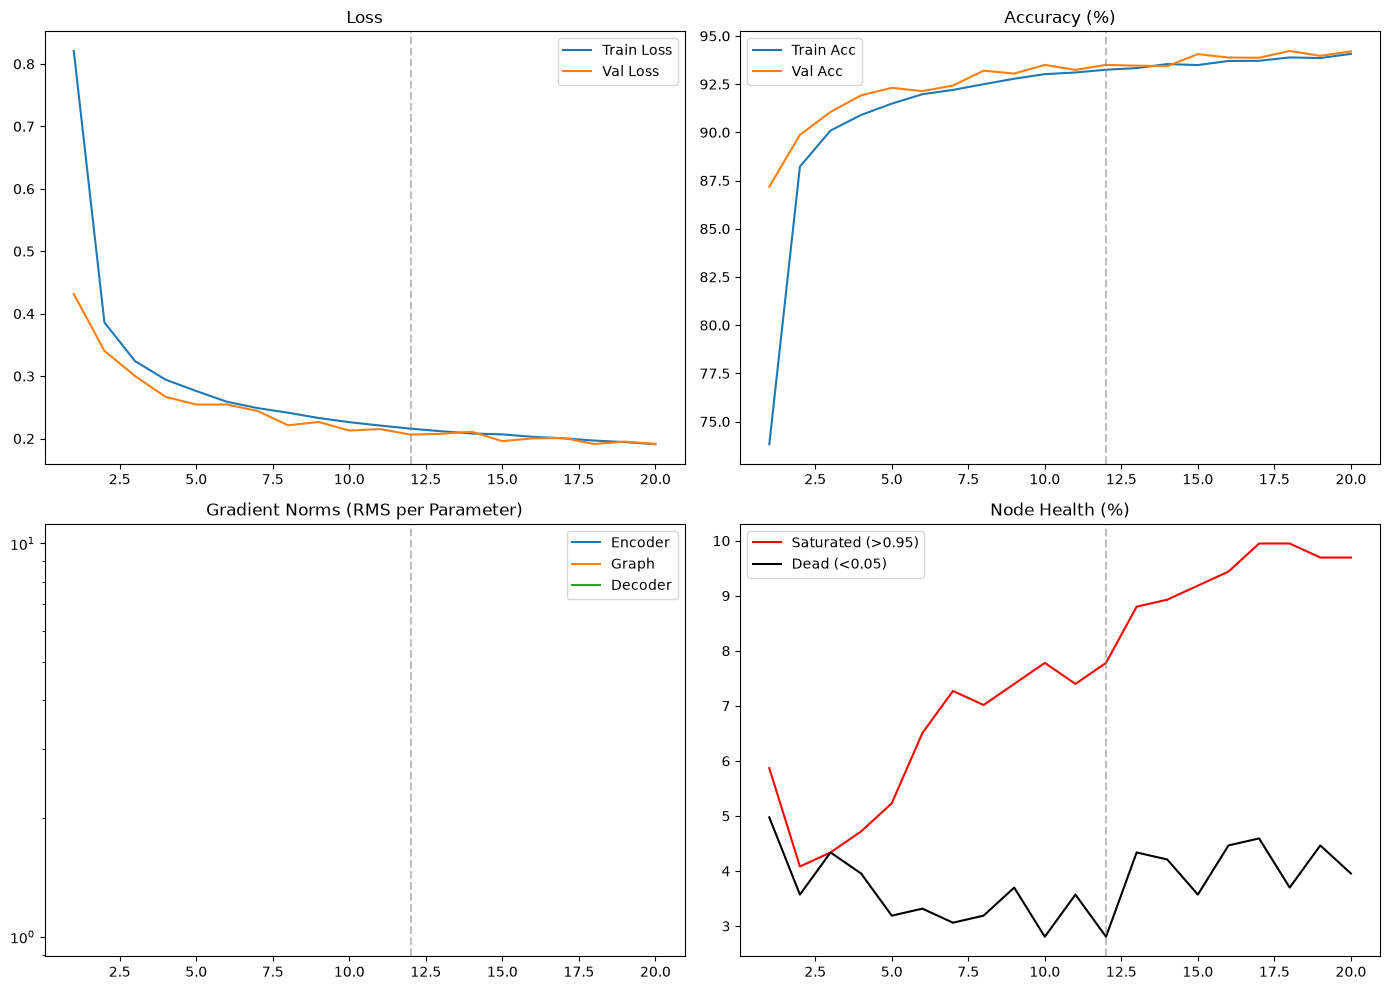

Loading Interactive Topology & Heatmap...


In [ ]:
# =====================================================================
# 5. Main Execution Workflow
# =====================================================================
if __name__ == "__main__":
    cfg = TrainingConfig() 
    print(f"Hardware utilized: {cfg.device.type.upper()}")
    print(f"Dataset: {cfg.dataset_name} | Inputs: {cfg.input_features} | Classes: {cfg.output_classes}")
    print(f"MLP Activation: {cfg.mlp_activation.upper()} | Encoder Type: {cfg.encoder_type.upper()}")

    train_loader, val_loader = get_image_dataloaders(cfg.dataset_name, cfg.base_batch_size, cfg.encoder_type)

    model = MultiHeadDirectedThinkingGraph(
        input_dim=cfg.input_features, output_dim=cfg.output_classes, 
        G=cfg.G, SF=cfg.SF, TF=cfg.TF, h=cfg.h, 
        encoder_dims=cfg.encoder_dims, decoder_dims=cfg.decoder_dims,
        use_second_graph_ring=cfg.use_second_graph_ring, 
        use_layernorm=cfg.use_layernorm, use_self_loops=cfg.use_self_loops,
        use_bidirectional=cfg.use_bidirectional, noise_sigma=cfg.noise_sigma,
        encoder_type=cfg.encoder_type, mlp_activation=cfg.mlp_activation
    ).to(cfg.device)
    
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay) 
    
    hist = {
        't_loss': [], 't_acc': [], 'v_loss': [], 'v_acc': [],
        'g_enc': [], 'g_graph': [], 'g_dec': [], 'sat': [], 'dead': []
    }
    
    diagnostic_sample, _ = next(iter(val_loader))
    diagnostic_sample = diagnostic_sample[0:1]
    
    visual_history_weights = []
    visual_history_activations = []

    print(f"\nStarting training for {cfg.epochs} epochs...")
    
    for epoch in range(cfg.epochs):
        accum_steps = get_accumulation_steps(epoch, cfg.epochs, cfg.use_dynamic_accum)
        
        # optimizer = check_optimizer_swap(epoch, cfg.epochs, optimizer, model)
        
        t_loss, t_acc, (ge, gg, gd) = train_epoch(model, train_loader, optimizer, criterion, accum_steps, cfg.device)
        v_loss, v_acc = validate_epoch(model, val_loader, criterion, cfg.device)
        state_diag = extract_node_diagnostics(model, diagnostic_sample, cfg.device)
        
        hist['t_loss'].append(t_loss); hist['t_acc'].append(t_acc)
        hist['v_loss'].append(v_loss); hist['v_acc'].append(v_acc)
        hist['g_enc'].append(ge); hist['g_graph'].append(gg); hist['g_dec'].append(gd)
        hist['sat'].append(state_diag['sat_pct']); hist['dead'].append(state_diag['dead_pct'])
        
        visual_history_weights.append(state_diag['weight_matrix'])
        visual_history_activations.append(state_diag['activations'])
        
        if (epoch + 1) % max(1, int(cfg.epochs * 0.1)) == 0 or epoch == 0:
            print(f"Epoch {epoch+1:03d}/{cfg.epochs} | Accum: {accum_steps}x | "
                  f"Train Acc: {t_acc:5.1f}% | Val Acc: {v_acc:5.1f}%")

    # =====================================================================
    # 6. Plotting
    # =====================================================================
    print("\nTraining complete. Rendering plots...")
    epochs_range = range(1, cfg.epochs + 1)
    
    fig = plt.figure(figsize=(14, 10))
    gs = fig.add_gridspec(2, 2)
    
    ax_loss = fig.add_subplot(gs[0, 0])
    ax_acc = fig.add_subplot(gs[0, 1])
    ax_grad = fig.add_subplot(gs[1, 0])
    ax_health = fig.add_subplot(gs[1, 1])

    ax_loss.plot(epochs_range, hist['t_loss'], label='Train Loss')
    ax_loss.plot(epochs_range, hist['v_loss'], label='Val Loss')
    ax_loss.set_title('Loss'); ax_loss.legend()

    ax_acc.plot(epochs_range, hist['t_acc'], label='Train Acc')
    ax_acc.plot(epochs_range, hist['v_acc'], label='Val Acc')
    ax_acc.set_title('Accuracy (%)'); ax_acc.legend()

    ax_grad.plot(epochs_range, hist['g_enc'], label='Encoder')
    ax_grad.plot(epochs_range, hist['g_graph'], label='Graph')
    ax_grad.plot(epochs_range, hist['g_dec'], label='Decoder')
    ax_grad.set_yscale('log')
    ax_grad.set_title('Gradient Norms (RMS per Parameter)'); ax_grad.legend()

    ax_health.plot(epochs_range, hist['sat'], color='red', label='Saturated (>0.95)')
    ax_health.plot(epochs_range, hist['dead'], color='black', label='Dead (<0.05)')
    ax_health.set_title('Node Health (%)'); ax_health.legend()

    swap_point = int(cfg.epochs * 0.60)
    for ax in [ax_loss, ax_acc, ax_grad, ax_health]:
        ax.axvline(swap_point, color='gray', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.show()

    # =====================================================================
    # 7. Interactive Widgets
    # =====================================================================
    print("Loading Interactive Topology & Heatmap...")
    
    G_nx = nx.from_numpy_array(model.base_mask.numpy().T, create_using=nx.DiGraph)
    
    pos = {i: (np.cos(2*np.pi*i/cfg.G), np.sin(2*np.pi*i/cfg.G)) for i in range(cfg.G)}
    if cfg.use_second_graph_ring:
        for i in range(cfg.G):
            pos[i + cfg.G] = (np.cos(2*np.pi*i/cfg.G) + 3.0, np.sin(2*np.pi*i/cfg.G))

    activations_tensor = np.array(visual_history_activations)
    vmax_act, vmin_act = np.max(activations_tensor), np.min(activations_tensor)

    def plot_activations(epoch_idx, t, head_idx):
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.set_title(f"Head {head_idx} Activations | Epoch {epoch_idx + 1}, t = {t}")
        ax.axis('off')
        
        start_idx = head_idx * model.nodes_per_head
        end_idx = (head_idx + 1) * model.nodes_per_head
        head_activations = activations_tensor[epoch_idx, t, start_idx:end_idx]
        
        nodes = nx.draw_networkx_nodes(
            G_nx, pos, ax=ax, node_size=300, 
            node_color=head_activations, cmap=plt.cm.coolwarm, vmin=vmin_act, vmax=vmax_act
        )
        nx.draw_networkx_labels(G_nx, pos, font_size=8, ax=ax)
        nx.draw_networkx_edges(G_nx, pos, ax=ax, node_size=300, arrowstyle='->', alpha=0.1)
        fig.colorbar(nodes, ax=ax, label="Activation Value")
        plt.show()

    display(widgets.interactive(
        plot_activations, 
        epoch_idx=widgets.IntSlider(value=cfg.epochs-1, min=0, max=cfg.epochs-1, step=1, continuous_update=False), 
        t=widgets.IntSlider(value=0, min=0, max=cfg.TF, step=1, continuous_update=False),
        head_idx=widgets.IntSlider(value=0, min=0, max=cfg.h-1, step=1, description="Head", continuous_update=False)
    ))